In [ ]:
print("CAMPUS SHUTTLE ROUTING SYSTEM")
print("--------------------------------")
print("Welcome to our DAA Project!")
print("Project Status: Started Successfully")

CAMPUS SHUTTLE ROUTING SYSTEM
--------------------------------
Welcome to our DAA Project!
Project Status: Started Successfully


In [ ]:
locations = {
    "A": "Main Gate",
    "B": "Hostel",
    "C": "Academic Block",
    "D": "Library",
    "E": "Cafeteria",
    "F": "Sports Complex",
    "G": "Admin Block",
    "H": "Auditorium",
    "I": "Medical Centre",
    "J": "Parking Area"
}

print("Campus Locations:")

for code, name in locations.items():
    print(code, ":", name)

Campus Locations:
A : Main Gate
B : Hostel
C : Academic Block
D : Library
E : Cafeteria
F : Sports Complex
G : Admin Block
H : Auditorium
I : Medical Centre
J : Parking Area


In [ ]:
roads = [
    ("A", "B", 4),
    ("A", "G", 3),
    ("B", "C", 5),
    ("B", "I", 4),
    ("C", "D", 2),
    ("C", "G", 3),
    ("D", "E", 3),
    ("D", "H", 4),
    ("E", "F", 5),
    ("F", "J", 3),
    ("G", "H", 4),
    ("H", "I", 3),
    ("I", "J", 5)
]

print("Campus Roads:")

for start, end, time in roads:
    print(locations[start], "to", locations[end], "=", time, "minutes")

Campus Roads:
Main Gate to Hostel = 4 minutes
Main Gate to Admin Block = 3 minutes
Hostel to Academic Block = 5 minutes
Hostel to Medical Centre = 4 minutes
Academic Block to Library = 2 minutes
Academic Block to Admin Block = 3 minutes
Library to Cafeteria = 3 minutes
Library to Auditorium = 4 minutes
Cafeteria to Sports Complex = 5 minutes
Sports Complex to Parking Area = 3 minutes
Admin Block to Auditorium = 4 minutes
Auditorium to Medical Centre = 3 minutes
Medical Centre to Parking Area = 5 minutes


In [ ]:
graph = {}

# Create an empty list for every location
for location in locations:
    graph[location] = []

# Add road connections
for start, end, time in roads:
    graph[start].append((end, time))
    graph[end].append((start, time))

# Display the graph
print("CAMPUS GRAPH")
print("--------------------")

for location, connections in graph.items():
    print(locations[location], ":", connections)

CAMPUS GRAPH
--------------------
Main Gate : [('B', 4), ('G', 3)]
Hostel : [('A', 4), ('C', 5), ('I', 4)]
Academic Block : [('B', 5), ('D', 2), ('G', 3)]
Library : [('C', 2), ('E', 3), ('H', 4)]
Cafeteria : [('D', 3), ('F', 5)]
Sports Complex : [('E', 5), ('J', 3)]
Admin Block : [('A', 3), ('C', 3), ('H', 4)]
Auditorium : [('D', 4), ('G', 4), ('I', 3)]
Medical Centre : [('B', 4), ('H', 3), ('J', 5)]
Parking Area : [('F', 3), ('I', 5)]


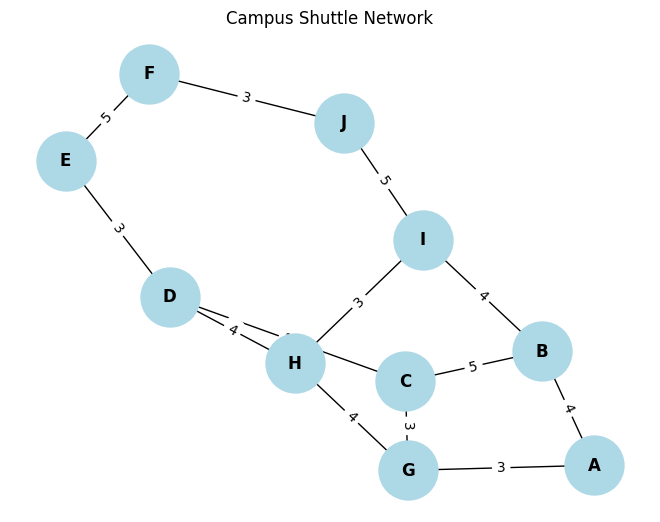

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

# Create a network graph
G = nx.Graph()

# Add locations
for code, name in locations.items():
    G.add_node(code, label=name)

# Add roads with travel times
for start, end, time in roads:
    G.add_edge(start, end, weight=time)

# Arrange locations visually
pos = nx.spring_layout(G, seed=42)

# Draw locations and roads
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1800,
    font_size=12,
    font_weight="bold"
)

# Display travel times
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("Campus Shuttle Network")
plt.show()

In [ ]:
import heapq

def prim(graph, start):

    visited = set()
    min_heap = [(0, start, None)]

    mst = []
    total_cost = 0

    while min_heap:

        weight, node, parent = heapq.heappop(min_heap)

        if node in visited:
            continue

        visited.add(node)

        if parent is not None:
            mst.append((parent, node, weight))
            total_cost += weight

        for neighbor, edge_weight in graph[node]:

            if neighbor not in visited:
                heapq.heappush(
                    min_heap,
                    (edge_weight, neighbor, node)
                )

    return mst, total_cost

In [ ]:
mst, total_cost = prim(graph, "A")

print("MINIMUM SPANNING TREE")
print("----------------------")

for u, v, w in mst:
    print(locations[u], "to", locations[v], "=", w, "minutes")

print("----------------------")
print("Total MST Cost:", total_cost, "minutes")
print("Number of Edges:", len(mst))

MINIMUM SPANNING TREE
----------------------
Main Gate to Admin Block = 3 minutes
Admin Block to Academic Block = 3 minutes
Academic Block to Library = 2 minutes
Library to Cafeteria = 3 minutes
Main Gate to Hostel = 4 minutes
Library to Auditorium = 4 minutes
Auditorium to Medical Centre = 3 minutes
Cafeteria to Sports Complex = 5 minutes
Sports Complex to Parking Area = 3 minutes
----------------------
Total MST Cost: 30 minutes
Number of Edges: 9


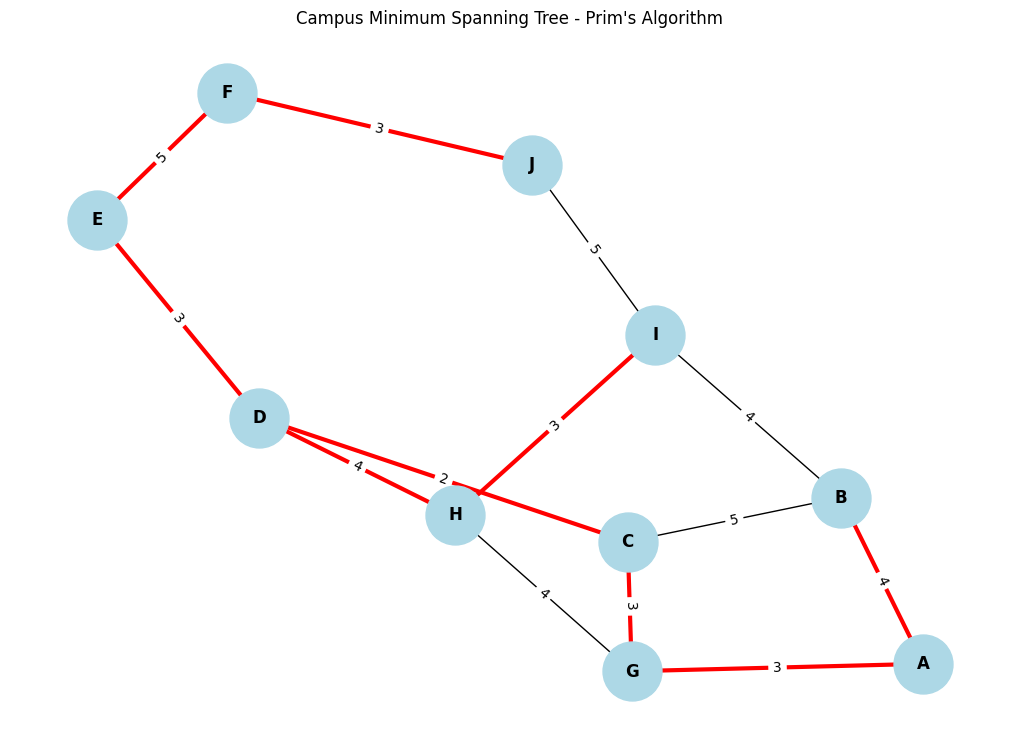

In [ ]:
plt.figure(figsize=(10, 7))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1800,
    font_weight="bold"
)

# Highlight MST edges
mst_edges = [(u, v) for u, v, w in mst]

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=mst_edges,
    edge_color="red",
    width=3
)

# Show travel times
nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

plt.title("Campus Minimum Spanning Tree - Prim's Algorithm")
plt.show()

In [ ]:
def kruskal(graph):

    edges = []

    for node in graph:
        for neighbor, weight in graph[node]:
            if node < neighbor:
                edges.append((weight, node, neighbor))

    edges.sort()

    parent = {node: node for node in graph}

    def find(node):
        if parent[node] != node:
            parent[node] = find(parent[node])
        return parent[node]

    mst = []
    total_cost = 0

    for weight, u, v in edges:

        root_u = find(u)
        root_v = find(v)

        if root_u != root_v:
            mst.append((u, v, weight))
            total_cost += weight
            parent[root_u] = root_v

    return mst, total_cost

In [ ]:
kruskal_mst, kruskal_cost = kruskal(graph)

print("KRUSKAL'S ALGORITHM")
print("----------------------")

for u, v, w in kruskal_mst:
    print(locations[u], "to", locations[v], "=", w, "minutes")

print("----------------------")
print("Total MST Cost:", kruskal_cost, "minutes")
print("Number of Edges:", len(kruskal_mst))

KRUSKAL'S ALGORITHM
----------------------
Academic Block to Library = 2 minutes
Main Gate to Admin Block = 3 minutes
Academic Block to Admin Block = 3 minutes
Library to Cafeteria = 3 minutes
Sports Complex to Parking Area = 3 minutes
Auditorium to Medical Centre = 3 minutes
Main Gate to Hostel = 4 minutes
Hostel to Medical Centre = 4 minutes
Cafeteria to Sports Complex = 5 minutes
----------------------
Total MST Cost: 30 minutes
Number of Edges: 9


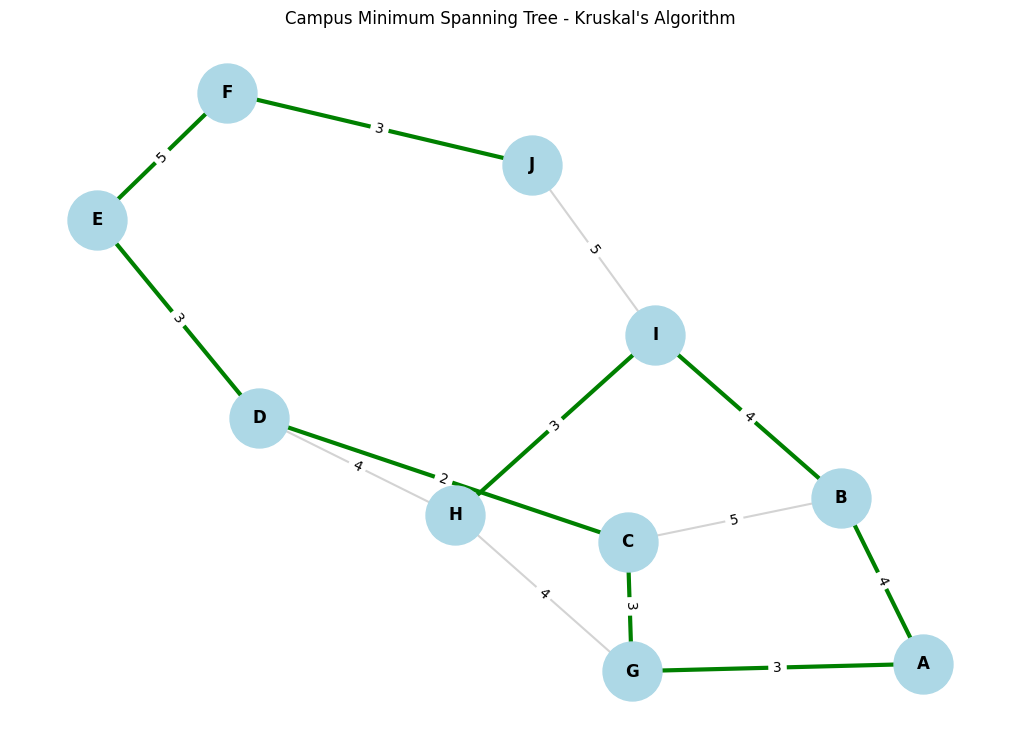

In [ ]:
plt.figure(figsize=(10, 7))

# Draw all campus roads in grey
nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1800,
    font_weight="bold",
    edge_color="lightgray",
    width=1.5
)

# Highlight Kruskal's selected roads in green
kruskal_edges = [(u, v) for u, v, w in kruskal_mst]

nx.draw_networkx_edges(
    G,
    pos,
    edgelist=kruskal_edges,
    edge_color="green",
    width=3
)

# Display travel times
nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

plt.title("Campus Minimum Spanning Tree - Kruskal's Algorithm")
plt.show()

In [ ]:
import heapq

def dijkstra(graph, start):

    distances = {node: float('inf') for node in graph}
    previous = {node: None for node in graph}

    distances[start] = 0

    pq = [(0, start)]

    while pq:

        current_distance, current_node = heapq.heappop(pq)

        if current_distance > distances[current_node]:
            continue

        for neighbor, weight in graph[current_node]:

            new_distance = current_distance + weight

            if new_distance < distances[neighbor]:

                distances[neighbor] = new_distance
                previous[neighbor] = current_node

                heapq.heappush(
                    pq, (new_distance, neighbor)
                )

    return distances, previous

In [ ]:
distances, previous = dijkstra(graph, "B")

destination = "D"

print("Shortest travel time:")
print(locations["B"], "to", locations[destination])

print("Time:", distances[destination], "minutes")

Shortest travel time:
Hostel to Library
Time: 7 minutes


In [ ]:
def get_path(previous, start, destination):

    path = []
    current = destination

    while current is not None:
        path.append(current)
        current = previous[current]

    path.reverse()

    return path


path = get_path(previous, "B", "D")

print("Shortest Route:")

for node in path:
    print(locations[node], end=" -> ")

print("\nTotal Time:", distances["D"], "minutes")

Shortest Route:
Hostel -> Academic Block -> Library -> 
Total Time: 7 minutes


In [ ]:
print("CAMPUS SHUTTLE ROUTE FINDER")
print("----------------------------")

print("Available Locations:")

for code, name in locations.items():
    print(code, ":", name)

source = input("\nEnter source code: ").upper()
destination = input("Enter destination code: ").upper()

if source in graph and destination in graph:

    distances, previous = dijkstra(graph, source)

    path = get_path(previous, source, destination)

    print("\nSHORTEST ROUTE")

    for node in path:
        print(locations[node], end=" -> ")

    print("\nTotal Travel Time:", distances[destination], "minutes")

else:
    print("Invalid location code!")

CAMPUS SHUTTLE ROUTE FINDER
----------------------------
Available Locations:
A : Main Gate
B : Hostel
C : Academic Block
D : Library
E : Cafeteria
F : Sports Complex
G : Admin Block
H : Auditorium
I : Medical Centre
J : Parking Area

Enter source code: B
Enter destination code: D

SHORTEST ROUTE
Hostel -> Academic Block -> Library -> 
Total Travel Time: 7 minutes


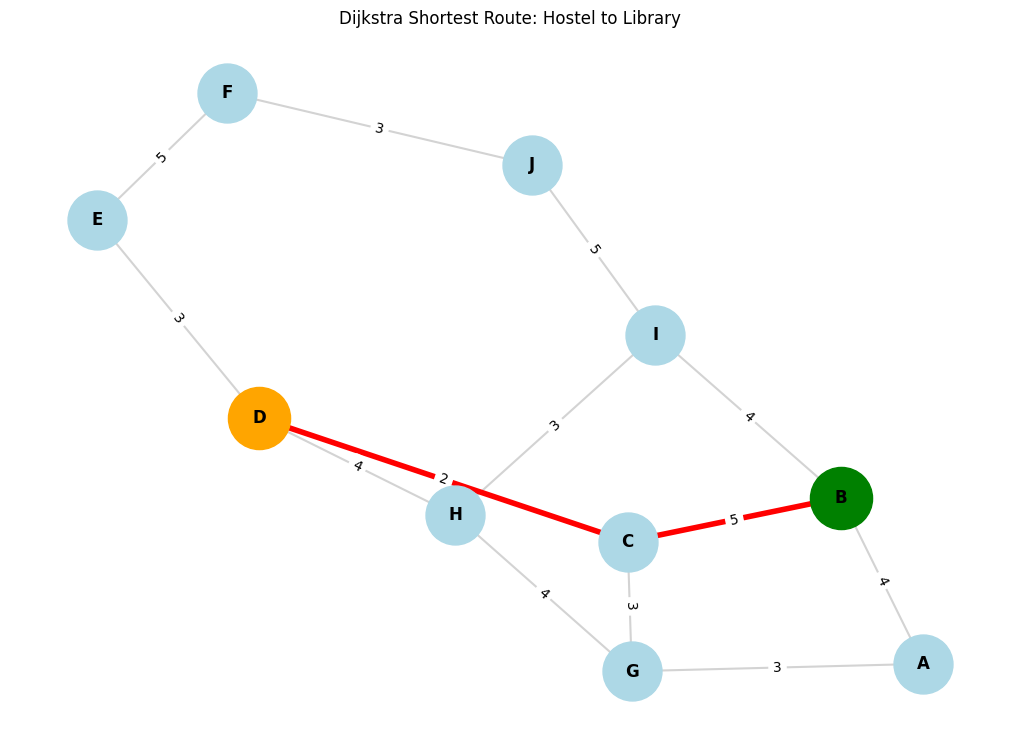

Route: Hostel -> Academic Block -> Library
Total Travel Time: 7 minutes


In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

# Select source and destination
source = "B"
destination = "D"

# Find shortest path
distances, previous = dijkstra(graph, source)
path = get_path(previous, source, destination)

# Convert path into edges
path_edges = list(zip(path, path[1:]))

# Draw graph
plt.figure(figsize=(10, 7))

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="lightblue",
    node_size=1800,
    edge_color="lightgray",
    width=1.5,
    font_weight="bold"
)

# Highlight shortest route
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=path_edges,
    edge_color="red",
    width=4
)

# Highlight source and destination
nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=[source],
    node_color="green",
    node_size=2000
)

nx.draw_networkx_nodes(
    G,
    pos,
    nodelist=[destination],
    node_color="orange",
    node_size=2000
)

# Show road travel times
nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels
)

plt.title(
    f"Dijkstra Shortest Route: {locations[source]} to {locations[destination]}"
)

plt.show()

print("Route:", " -> ".join(locations[node] for node in path))
print("Total Travel Time:", distances[destination], "minutes")

In [ ]:
def floyd_warshall(graph):

    nodes = list(graph.keys())

    dist = {
        u: {v: float('inf') for v in nodes}
        for u in nodes
    }

    for node in nodes:
        dist[node][node] = 0

    for u in graph:
        for v, weight in graph[u]:
            dist[u][v] = weight

    for k in nodes:
        for i in nodes:
            for j in nodes:

                new_distance = dist[i][k] + dist[k][j]

                if new_distance < dist[i][j]:
                    dist[i][j] = new_distance

    return dist

In [ ]:
dist = floyd_warshall(graph)

print("CAMPUS SHORTEST TRAVEL TIME MATRIX")
print("----------------------------------")

print("    ", end="")

for node in locations:
    print(node, end="   ")

print()

for i in locations:

    print(i, end="   ")

    for j in locations:

        print(dist[i][j], end="   ")

    print()

CAMPUS SHORTEST TRAVEL TIME MATRIX
----------------------------------
    A   B   C   D   E   F   G   H   I   J   
A   0   4   6   8   11   16   3   7   8   13   
B   4   0   5   7   10   12   7   7   4   9   
C   6   5   0   2   5   10   3   6   9   13   
D   8   7   2   0   3   8   5   4   7   11   
E   11   10   5   3   0   5   8   7   10   8   
F   16   12   10   8   5   0   13   11   8   3   
G   3   7   3   5   8   13   0   4   7   12   
H   7   7   6   4   7   11   4   0   3   8   
I   8   4   9   7   10   8   7   3   0   5   
J   13   9   13   11   8   3   12   8   5   0   


In [ ]:
print("Hostel to Library:",
      dist["B"]["D"], "minutes")

print("Main Gate to Sports Complex:",
      dist["A"]["F"], "minutes")

Hostel to Library: 7 minutes
Main Gate to Sports Complex: 16 minutes


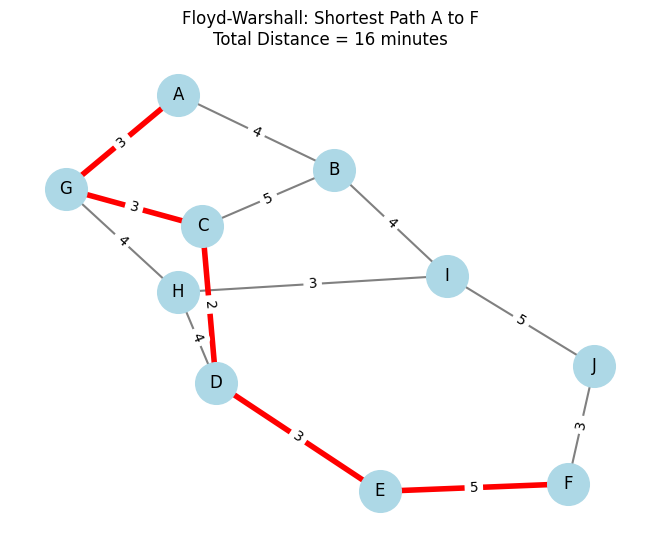

Shortest Path: A → G → C → D → E → F
Total Travel Time: 16 minutes


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

source = "A"
destination = "F"

# Get shortest path using Dijkstra's previous function
distances, previous = dijkstra(graph, source)
path = get_path(previous, source, destination)

# Create graph
G = nx.Graph()

for start, end, time in roads:
    G.add_edge(start, end, weight=time)

# Draw all roads
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightblue",
    node_size=900,
    font_size=12,
    edge_color="gray",
    width=1.5
)

# Highlight shortest path
path_edges = list(zip(path, path[1:]))

nx.draw_networkx_edges(
    G, pos,
    edgelist=path_edges,
    edge_color="red",
    width=4
)

# Show travel times
edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title(f"Floyd-Warshall: Shortest Path {source} to {destination}\nTotal Distance = {distances[destination]} minutes")
plt.show()

print("Shortest Path:", " → ".join(path))
print("Total Travel Time:", distances[destination], "minutes")

In [ ]:
# Greedy Algorithm for Shuttle Scheduling

requests = [
    {"stop": "Hostel", "passengers": 12, "waiting_time": 10},
    {"stop": "Library", "passengers": 5, "waiting_time": 20},
    {"stop": "Cafeteria", "passengers": 15, "waiting_time": 5},
    {"stop": "Sports Complex", "passengers": 8, "waiting_time": 15},
    {"stop": "Academic Block", "passengers": 10, "waiting_time": 12}
]

# Calculate priority score
for request in requests:
    request["priority"] = request["passengers"] * request["waiting_time"]

# Sort requests by highest priority
requests.sort(key=lambda x: x["priority"], reverse=True)

print("GREEDY SHUTTLE SCHEDULING")
print("-------------------------")

for i, request in enumerate(requests, start=1):
    print(
        i, ".", request["stop"],
        "| Passengers:", request["passengers"],
        "| Waiting:", request["waiting_time"], "min",
        "| Priority:", request["priority"]
    )

GREEDY SHUTTLE SCHEDULING
-------------------------
1 . Hostel | Passengers: 12 | Waiting: 10 min | Priority: 120
2 . Sports Complex | Passengers: 8 | Waiting: 15 min | Priority: 120
3 . Academic Block | Passengers: 10 | Waiting: 12 min | Priority: 120
4 . Library | Passengers: 5 | Waiting: 20 min | Priority: 100
5 . Cafeteria | Passengers: 15 | Waiting: 5 min | Priority: 75


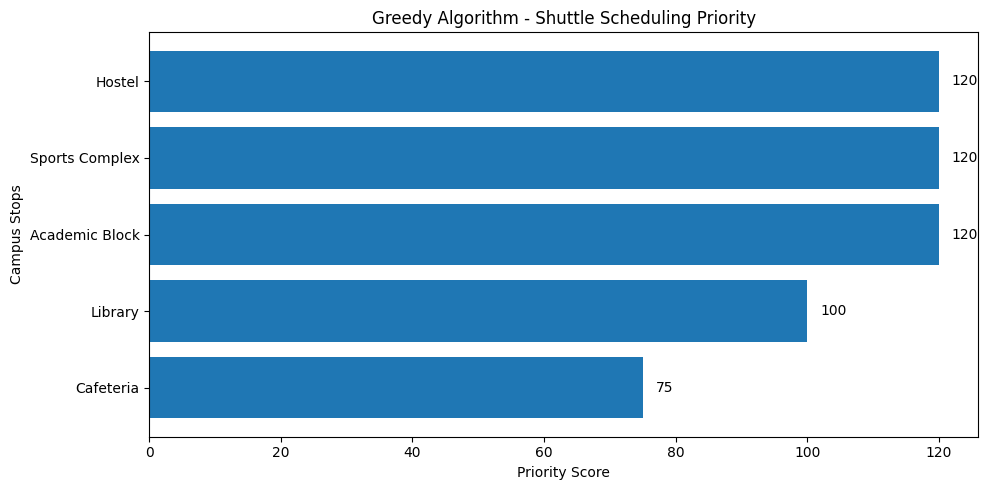

In [ ]:
import matplotlib.pyplot as plt

stops = [request["stop"] for request in requests]
priorities = [request["priority"] for request in requests]

plt.figure(figsize=(10, 5))

plt.barh(stops, priorities)

plt.xlabel("Priority Score")
plt.ylabel("Campus Stops")
plt.title("Greedy Algorithm - Shuttle Scheduling Priority")

plt.gca().invert_yaxis()

for i, value in enumerate(priorities):
    plt.text(value + 2, i, str(value), va="center")

plt.tight_layout()
plt.show()

In [ ]:
# Dynamic Programming - Shuttle Capacity Optimization

passengers = [12, 8, 10, 5, 15]
waiting_times = [10, 15, 12, 20, 5]

capacity = 25
n = len(passengers)

# DP table
dp = [[0 for _ in range(capacity + 1)] for _ in range(n + 1)]

for i in range(1, n + 1):
    for w in range(capacity + 1):

        dp[i][w] = dp[i - 1][w]

        if passengers[i - 1] <= w:
            dp[i][w] = max(
                dp[i][w],
                waiting_times[i - 1] + dp[i - 1][w - passengers[i - 1]]
            )

print("Maximum total waiting time served:", dp[n][capacity])

Maximum total waiting time served: 47


In [ ]:
# Find selected stops from DP table

selected = []
w = capacity

for i in range(n, 0, -1):
    if dp[i][w] != dp[i - 1][w]:
        selected.append(i - 1)
        w -= passengers[i - 1]

selected.reverse()

selected_stops = [locations_list for locations_list in selected]

stop_names = ["Hostel", "Sports Complex", "Academic Block", "Library", "Cafeteria"]

print("SELECTED STOPS:")
for i in selected:
    print(stop_names[i])

print("Total Passengers:", sum(passengers[i] for i in selected))
print("Total Waiting Time Served:", sum(waiting_times[i] for i in selected))
print("Shuttle Capacity:", capacity)

SELECTED STOPS:
Sports Complex
Academic Block
Library
Total Passengers: 23
Total Waiting Time Served: 47
Shuttle Capacity: 25


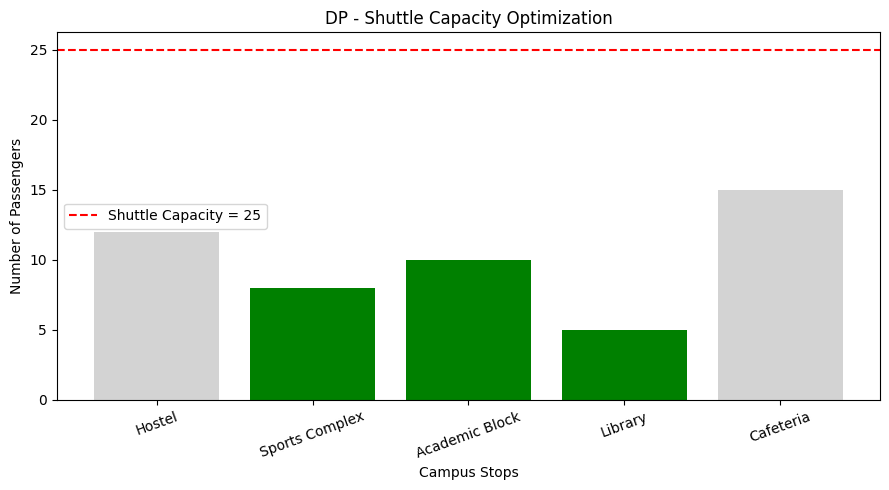

In [ ]:
import matplotlib.pyplot as plt

colors = ["green" if i in selected else "lightgray" for i in range(n)]

plt.figure(figsize=(9, 5))

plt.bar(stop_names, passengers, color=colors)

plt.axhline(y=capacity, color="red", linestyle="--",
            label="Shuttle Capacity = 25")

plt.xlabel("Campus Stops")
plt.ylabel("Number of Passengers")
plt.title("DP - Shuttle Capacity Optimization")

plt.legend()
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
import time

# Dijkstra execution time
start = time.perf_counter()
dijkstra(graph, "A")
dijkstra_time = time.perf_counter() - start

# Floyd-Warshall execution time
start = time.perf_counter()
floyd_warshall(graph)
floyd_time = time.perf_counter() - start

print("ALGORITHM PERFORMANCE")
print("----------------------")
print("Dijkstra:", dijkstra_time, "seconds")
print("Floyd-Warshall:", floyd_time, "seconds")

ALGORITHM PERFORMANCE
----------------------
Dijkstra: 0.00010549799981163233 seconds
Floyd-Warshall: 0.00033998500020970823 seconds


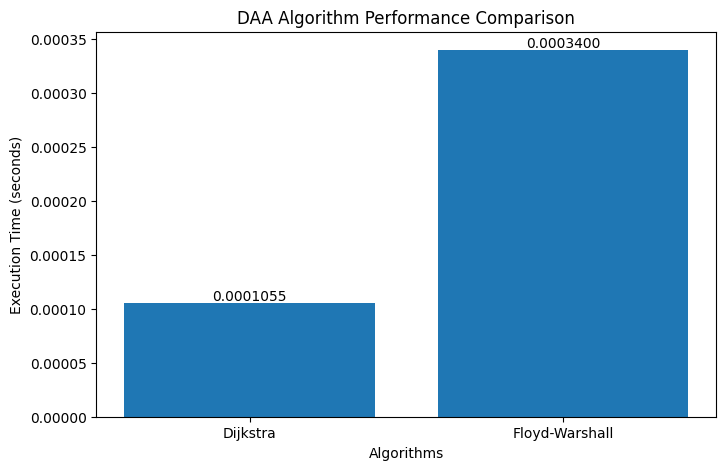

In [ ]:
import matplotlib.pyplot as plt

algorithms = ["Dijkstra", "Floyd-Warshall"]
times = [dijkstra_time, floyd_time]

plt.figure(figsize=(8, 5))

plt.bar(algorithms, times)

plt.xlabel("Algorithms")
plt.ylabel("Execution Time (seconds)")
plt.title("DAA Algorithm Performance Comparison")

for i, value in enumerate(times):
    plt.text(i, value, f"{value:.7f}", ha="center", va="bottom")

plt.show()

In [ ]:
import random
import time
import matplotlib.pyplot as plt

def generate_graph(n, density=0.15):
    G = nx.gnp_random_graph(n, density, seed=42)

    # Ensure the graph is connected
    if not nx.is_connected(G):
        components = list(nx.connected_components(G))
        for i in range(len(components) - 1):
            u = next(iter(components[i]))
            v = next(iter(components[i + 1]))
            G.add_edge(u, v)

    graph_data = {i: [] for i in range(n)}

    for u, v in G.edges():
        weight = random.randint(1, 10)
        graph_data[u].append((v, weight))
        graph_data[v].append((u, weight))

    return graph_data

sizes = [10, 50, 100, 200]

dijkstra_times = []
floyd_times = []

for size in sizes:
    test_graph = generate_graph(size)

    start = time.perf_counter()
    dijkstra(test_graph, 0)
    dijkstra_times.append(time.perf_counter() - start)

    start = time.perf_counter()
    floyd_warshall(test_graph)
    floyd_times.append(time.perf_counter() - start)

print("GRAPH SIZE | DIJKSTRA | FLOYD-WARSHALL")

for i in range(len(sizes)):
    print(
        sizes[i], "|",
        round(dijkstra_times[i], 6), "|",
        round(floyd_times[i], 6)
    )

GRAPH SIZE | DIJKSTRA | FLOYD-WARSHALL
10 | 2.2e-05 | 0.000286
50 | 9.4e-05 | 0.031059
100 | 0.000302 | 0.208963
200 | 0.00094 | 1.704437


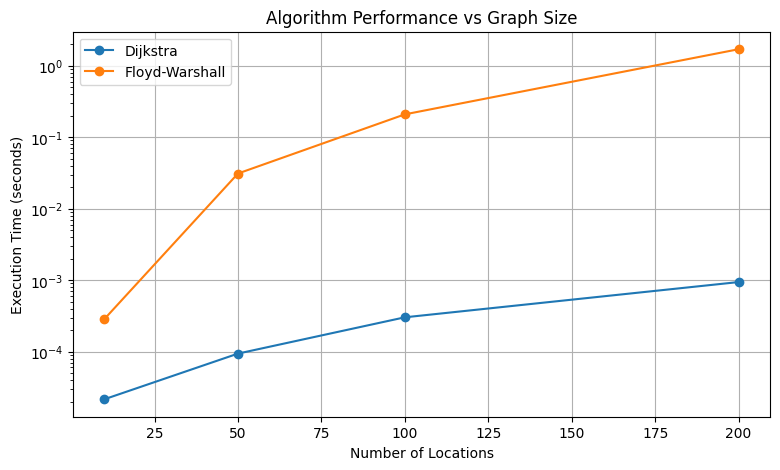

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(sizes, dijkstra_times, marker='o', label="Dijkstra")
plt.plot(sizes, floyd_times, marker='o', label="Floyd-Warshall")

plt.xlabel("Number of Locations")
plt.ylabel("Execution Time (seconds)")
plt.title("Algorithm Performance vs Graph Size")

plt.yscale("log")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
densities = [0.1, 0.3, 0.5, 0.8]

density_dijkstra = []
density_floyd = []

for density in densities:

    test_graph = generate_graph(100, density)

    start = time.perf_counter()
    dijkstra(test_graph, 0)
    density_dijkstra.append(time.perf_counter() - start)

    start = time.perf_counter()
    floyd_warshall(test_graph)
    density_floyd.append(time.perf_counter() - start)

print("DENSITY | DIJKSTRA | FLOYD-WARSHALL")

for i in range(len(densities)):
    print(
        densities[i], "|",
        round(density_dijkstra[i], 6), "|",
        round(density_floyd[i], 6)
    )

DENSITY | DIJKSTRA | FLOYD-WARSHALL
0.1 | 0.000265 | 0.223728
0.3 | 0.000489 | 0.211154
0.5 | 0.000583 | 0.215494
0.8 | 0.00093 | 0.221276


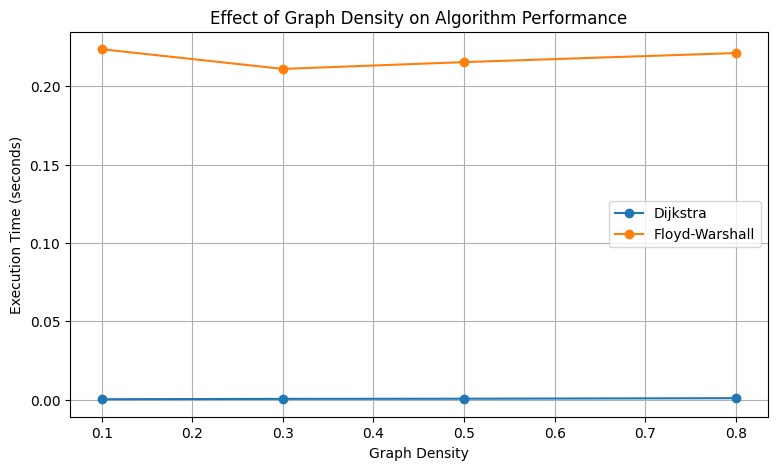

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(densities, density_dijkstra, marker='o', label="Dijkstra")
plt.plot(densities, density_floyd, marker='o', label="Floyd-Warshall")

plt.xlabel("Graph Density")
plt.ylabel("Execution Time (seconds)")
plt.title("Effect of Graph Density on Algorithm Performance")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
capacities = [10, 15, 20, 25, 30, 35]

max_values = []

for cap in capacities:

    dp_test = [[0 for _ in range(cap + 1)] for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(cap + 1):

            dp_test[i][w] = dp_test[i - 1][w]

            if passengers[i - 1] <= w:
                dp_test[i][w] = max(
                    dp_test[i][w],
                    waiting_times[i - 1] +
                    dp_test[i - 1][w - passengers[i - 1]]
                )

    max_values.append(dp_test[n][cap])

print("CAPACITY | MAXIMUM WAITING TIME SCORE")

for i in range(len(capacities)):
    print(capacities[i], "|", max_values[i])

CAPACITY | MAXIMUM WAITING TIME SCORE
10 | 20
15 | 35
20 | 35
25 | 47
30 | 47
35 | 57


In [ ]:
capacities = [10, 15, 20, 25, 30, 35]

max_values = []

for cap in capacities:

    dp_test = [[0 for _ in range(cap + 1)] for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(cap + 1):

            dp_test[i][w] = dp_test[i - 1][w]

            if passengers[i - 1] <= w:
                dp_test[i][w] = max(
                    dp_test[i][w],
                    waiting_times[i - 1] +
                    dp_test[i - 1][w - passengers[i - 1]]
                )

    max_values.append(dp_test[n][cap])

print("CAPACITY | MAXIMUM WAITING TIME SCORE")

for i in range(len(capacities)):
    print(capacities[i], "|", max_values[i])

CAPACITY | MAXIMUM WAITING TIME SCORE
10 | 20
15 | 35
20 | 35
25 | 47
30 | 47
35 | 57


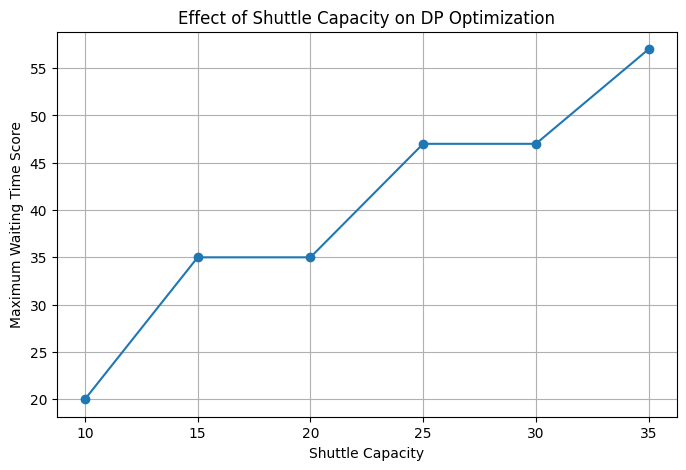

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(capacities, max_values, marker='o')

plt.xlabel("Shuttle Capacity")
plt.ylabel("Maximum Waiting Time Score")
plt.title("Effect of Shuttle Capacity on DP Optimization")

plt.grid(True)
plt.show()

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Graph Size": sizes,
    "Dijkstra Time (sec)": dijkstra_times,
    "Floyd-Warshall Time (sec)": floyd_times
})

print("FINAL ALGORITHM COMPARISON")
display(results)

FINAL ALGORITHM COMPARISON


,Graph Size,Dijkstra Time (sec),Floyd-Warshall Time (sec)
0,10,0.000022,0.000286
1,50,0.000094,0.031059
2,100,0.000302,0.208963
3,200,0.000940,1.704437


In [ ]:
complexity = pd.DataFrame({
    "Algorithm": [
        "Prim's",
        "Kruskal's",
        "Dijkstra's",
        "Floyd-Warshall",
        "Greedy Scheduling",
        "Dynamic Programming"
    ],
    "Time Complexity": [
        "O((V+E) log V)",
        "O(E log E)",
        "O((V+E) log V)",
        "O(V^3)",
        "O(n log n)",
        "O(n × W)"
    ],
    "Space Complexity": [
        "O(V+E)",
        "O(V)",
        "O(V)",
        "O(V^2)",
        "O(n)",
        "O(n × W)"
    ]
})

display(complexity)

,Algorithm,Time Complexity,Space Complexity
0,Prim's,O((V+E) log V),O(V+E)
1,Kruskal's,O(E log E),O(V)
2,Dijkstra's,O((V+E) log V),O(V)
3,Floyd-Warshall,O(V^3),O(V^2)
4,Greedy Scheduling,O(n log n),O(n)
5,Dynamic Programming,O(n × W),O(n × W)


In [ ]:
!pip -q install streamlit pyngrok

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 51.3 MB/s eta 0:00:00


In [12]:
%%writefile app.py
import streamlit as st
import networkx as nx
import matplotlib.pyplot as plt
import heapq
import time

st.set_page_config(
    page_title="Campus Shuttle Optimizer",
    page_icon="🚌",
    layout="wide"
)

# ---------------- CAMPUS DATA ----------------

locations = {
    "A": "Main Gate",
    "B": "Hostel",
    "C": "Academic Block",
    "D": "Library",
    "E": "Cafeteria",
    "F": "Sports Complex",
    "G": "Admin Block",
    "H": "Auditorium",
    "I": "Medical Centre",
    "J": "Parking Area"
}

roads = [
    ("A", "B", 4), ("A", "G", 3),
    ("B", "C", 5), ("B", "I", 4),
    ("C", "D", 2), ("C", "G", 3),
    ("D", "E", 3), ("D", "H", 4),
    ("E", "F", 5), ("F", "J", 3),
    ("G", "H", 4), ("H", "I", 3),
    ("I", "J", 5)
]

graph = {node: [] for node in locations}

for u, v, weight in roads:
    graph[u].append((v, weight))
    graph[v].append((u, weight))

# ---------------- ALGORITHMS ----------------

def dijkstra(graph, start):
    dist = {u: float("inf") for u in graph}
    prev = {u: None for u in graph}
    dist[start] = 0
    pq = [(0, start)]

    while pq:
        current_dist, u = heapq.heappop(pq)

        if current_dist > dist[u]:
            continue

        for v, weight in graph[u]:
            new_dist = current_dist + weight
            if new_dist < dist[v]:
                dist[v] = new_dist
                prev[v] = u
                heapq.heappush(pq, (new_dist, v))

    return dist, prev


def get_path(previous, start, end):
    if start == end:
        return [start]

    if previous[end] is None:
        return []

    path = []
    current = end

    while current is not None:
        path.append(current)
        current = previous[current]

    path.reverse()
    return path if path and path[0] == start else []


def floyd_warshall(graph):
    nodes = list(graph)
    dist = {u: {v: float("inf") for v in nodes} for u in nodes}

    for u in nodes:
        dist[u][u] = 0
        for v, weight in graph[u]:
            dist[u][v] = weight

    for k in nodes:
        for i in nodes:
            for j in nodes:
                dist[i][j] = min(
                    dist[i][j],
                    dist[i][k] + dist[k][j]
                )

    return dist


def prim_mst():
    start = "A"
    visited = {start}
    edges = []
    pq = []

    for v, weight in graph[start]:
        heapq.heappush(pq, (weight, start, v))

    while pq and len(visited) < len(graph):
        weight, u, v = heapq.heappop(pq)

        if v in visited:
            continue

        visited.add(v)
        edges.append((u, v, weight))

        for neighbor, w in graph[v]:
            if neighbor not in visited:
                heapq.heappush(pq, (w, v, neighbor))

    return edges


def kruskal_mst():
    parent = {u: u for u in graph}

    def find(u):
        while parent[u] != u:
            parent[u] = parent[parent[u]]
            u = parent[u]
        return u

    result = []

    for u, v, weight in sorted(roads, key=lambda x: x[2]):
        root_u, root_v = find(u), find(v)

        if root_u != root_v:
            parent[root_u] = root_v
            result.append((u, v, weight))

        if len(result) == len(graph) - 1:
            break

    return result


# ---------------- DASHBOARD ----------------

st.title("🚌 Campus Shuttle Routing & Capacity Scheduling")
st.caption("DAA Project | Interactive demonstration with synthetic data")
st.info("The locations, road times and passenger requests are illustrative, not measured campus data.")

page = st.sidebar.radio(
    "Navigation",
    [
        "Home",
        "Campus Network",
        "Shortest Route Finder",
        "Shuttle Scheduling",
        "Capacity Optimization",
        "Algorithm Comparison"
    ]
)

if page == "Home":
    st.header("Campus Shuttle Optimizer")

    c1, c2, c3 = st.columns(3)
    c1.metric("Campus Locations", len(locations))
    c2.metric("Road Connections", len(roads))
    c3.metric("Algorithms", 6)

    st.write("""
    This dashboard demonstrates graph algorithms for campus network
    connectivity, shortest routes, shuttle request prioritization,
    capacity optimization and performance analysis.
    """)

elif page == "Campus Network":
    st.header("Campus Network")

    G = nx.Graph()
    for u, name in locations.items():
        G.add_node(u, label=name)

    for u, v, w in roads:
        G.add_edge(u, v, weight=w)

    pos = nx.spring_layout(G, seed=42)
    fig, ax = plt.subplots(figsize=(10, 6))

    nx.draw(
        G, pos, ax=ax, with_labels=True,
        node_color="skyblue", node_size=1000,
        font_weight="bold", edge_color="gray"
    )
    nx.draw_networkx_edge_labels(
        G, pos, edge_labels=nx.get_edge_attributes(G, "weight"),
        ax=ax
    )

    labels = {u: f"{u}: {name}" for u, name in locations.items()}
    nx.draw_networkx_labels(
        G, pos, labels=labels, font_size=7, ax=ax,
        verticalalignment="bottom"
    )

    ax.set_title("Campus Locations and Road Travel Times (minutes)")
    st.pyplot(fig)
    plt.close(fig)

    st.subheader("Road Data")
    st.dataframe(
        [{"From": locations[u], "To": locations[v],
          "Travel Time (min)": w} for u, v, w in roads],
        use_container_width=True
    )

elif page == "Shortest Route Finder":
    st.header("Shortest Route Finder")

    source = st.selectbox(
        "Starting location", list(locations),
        format_func=lambda x: locations[x]
    )
    destination = st.selectbox(
        "Destination", list(locations), index=3,
        format_func=lambda x: locations[x]
    )

    if st.button("Find Shortest Route"):
        distances, previous = dijkstra(graph, source)
        path = get_path(previous, source, destination)

        if path:
            st.success(f"Minimum travel time: {distances[destination]} minutes")
            st.write(" → ".join(locations[x] for x in path))

            G = nx.Graph()
            G.add_weighted_edges_from(roads)
            pos = nx.spring_layout(G, seed=42)
            fig, ax = plt.subplots(figsize=(9, 5))

            nx.draw(
                G, pos, ax=ax, with_labels=True,
                node_color="lightblue", edge_color="lightgray",
                node_size=800
            )
            nx.draw_networkx_edges(
                G, pos, edgelist=list(zip(path, path[1:])),
                edge_color="red", width=4, ax=ax
            )
            nx.draw_networkx_edge_labels(
                G, pos, edge_labels=nx.get_edge_attributes(G, "weight"),
                ax=ax
            )

            st.pyplot(fig)
            plt.close(fig)
        else:
            st.error("No route exists.")

elif page == "Shuttle Scheduling":
    st.header("Greedy Shuttle Scheduling")
    st.write("Priority score = passenger count × waiting time")

    requests = [
        {"Stop": "Hostel", "Passengers": 12, "Waiting": 10},
        {"Stop": "Library", "Passengers": 5, "Waiting": 20},
        {"Stop": "Cafeteria", "Passengers": 15, "Waiting": 5},
        {"Stop": "Sports Complex", "Passengers": 8, "Waiting": 15},
        {"Stop": "Academic Block", "Passengers": 10, "Waiting": 12}
    ]

    for request in requests:
        request["Priority"] = request["Passengers"] * request["Waiting"]

    requests.sort(key=lambda x: x["Priority"], reverse=True)
    st.dataframe(requests, use_container_width=True)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(
        [r["Stop"] for r in requests],
        [r["Priority"] for r in requests]
    )
    ax.set_xlabel("Priority Score")
    ax.set_title("Greedy Shuttle Request Priorities")
    ax.invert_yaxis()
    st.pyplot(fig)
    plt.close(fig)

elif page == "Capacity Optimization":
    st.header("Dynamic Programming: Capacity Optimization")

    passenger_counts = [12, 8, 10, 5, 15]
    waiting_scores = [10, 15, 12, 20, 5]
    stops = ["Hostel", "Sports Complex", "Academic Block",
             "Library", "Cafeteria"]

    capacity = st.slider("Shuttle capacity", 5, 40, 25)
    n = len(stops)

    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        for w in range(capacity + 1):
            dp[i][w] = dp[i - 1][w]

            if passenger_counts[i - 1] <= w:
                dp[i][w] = max(
                    dp[i][w],
                    waiting_scores[i - 1]
                    + dp[i - 1][w - passenger_counts[i - 1]]
                )

    selected = []
    w = capacity

    for i in range(n, 0, -1):
        if dp[i][w] != dp[i - 1][w]:
            selected.append(i - 1)
            w -= passenger_counts[i - 1]

    selected.reverse()
    total_passengers = sum(passenger_counts[i] for i in selected)

    c1, c2, c3 = st.columns(3)
    c1.metric("Capacity", capacity)
    c2.metric("Passengers Selected", total_passengers)
    c3.metric("Maximum Score", dp[n][capacity])

    st.write("Selected stops:")
    if selected:
        st.dataframe([
            {
                "Stop": stops[i],
                "Passengers": passenger_counts[i],
                "Waiting Score": waiting_scores[i]
            } for i in selected
        ], use_container_width=True)
    else:
        st.write("No passenger groups selected.")

    fig, ax = plt.subplots(figsize=(9, 5))
    colors = [
        "green" if i in selected else "lightgray"
        for i in range(n)
    ]
    ax.bar(stops, passenger_counts, color=colors)
    ax.set_ylabel("Passengers")
    ax.set_title("Selected Passenger Groups (Green)")
    ax.tick_params(axis="x", rotation=20)
    st.pyplot(fig)
    plt.close(fig)

elif page == "Algorithm Comparison":
    st.header("Algorithm Comparison")

    st.subheader("Minimum Spanning Tree")
    prim_edges = prim_mst()
    kruskal_edges = kruskal_mst()

    c1, c2 = st.columns(2)
    c1.metric("Prim MST Total", sum(w for _, _, w in prim_edges))
    c2.metric("Kruskal MST Total", sum(w for _, _, w in kruskal_edges))

    st.write("Prim's selected edges")
    st.dataframe([
        {"From": locations[u], "To": locations[v], "Time": w}
        for u, v, w in prim_edges
    ], use_container_width=True)

    st.write("Kruskal's selected edges")
    st.dataframe([
        {"From": locations[u], "To": locations[v], "Time": w}
        for u, v, w in kruskal_edges
    ], use_container_width=True)

    st.subheader("Shortest-Path Algorithms")
    source = st.selectbox(
        "Source for comparison", list(locations),
        format_func=lambda x: locations[x],
        key="comparison_source"
    )

    start = time.perf_counter()
    dijkstra(graph, source)
    dijkstra_time = time.perf_counter() - start

    start = time.perf_counter()
    floyd_warshall(graph)
    floyd_time = time.perf_counter() - start

    st.write(f"Dijkstra runtime: {dijkstra_time:.8f} seconds")
    st.write(f"Floyd–Warshall runtime: {floyd_time:.8f} seconds")

    st.caption("Runtime values vary by run and machine. This small synthetic graph is for demonstration.")

Writing app.py


In [13]:
import os
print(os.path.exists("/content/app.py"))

True


In [14]:
!streamlit run /content/app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &

In [15]:
!cat /content/streamlit.log



2026-10-13 04:23:02.980 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.26.213.150:8501



In [16]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)
print("Your dashboard link:", public_url)

Your dashboard link: NgrokTunnel: "https://icy-zoom-outrank.ngrok-free.dev" -> "http://localhost:8501"


In [17]:
from google.colab import files
files.download("/content/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pkill -f "streamlit run app.py" || true

^C


In [ ]:
!streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [ ]:
!streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [ ]:
from pyngrok import ngrok

public_url = ngrok.connect(8501)
print("Your dashboard URL:", public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-11T12:00:44+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-11T12:00:44+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
CRITICAL:pyngrok.process.ngrok:t=2026-10-11T12:00:44+0000 lvl=crit msg="command failed" err="authentication failed: This ngrok session is not authenticated. ngrok requi

PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("3KY2MuJqYUNkGDdpPeN2w4sHfI2_5aScxbKLp737REhtkAzEp")

In [ ]:
public_url = ngrok.connect(8501)
print("Your dashboard URL:", public_url)

Your dashboard URL: NgrokTunnel: "https://icy-zoom-outrank.ngrok-free.dev" -> "http://localhost:8501"


In [ ]:
from google.colab import files
files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
!streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [2]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)
print("Your new dashboard link:", public_url)

ModuleNotFoundError: No module named 'pyngrok'

In [3]:
%pip install streamlit pyngrok networkx matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 57.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 96.0 MB/s eta 0:00:00


In [4]:
!streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &

In [5]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)
print("Your new dashboard link:", public_url)

ERROR:pyngrok.process.ngrok:t=2026-10-13T04:04:01+0000 lvl=eror msg="failed to reconnect session" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"
ERROR:pyngrok.process.ngrok:t=2026-10-13T04:04:01+0000 lvl=eror msg="session closing" obj=tunnels.session err="authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n"


PyngrokNgrokError: The ngrok process errored on start: authentication failed: This ngrok session is not authenticated. ngrok requires an account and a valid credential to start a session.\n\nSign up for an account: https://dashboard.ngrok.com/signup\nGet your credential: https://dashboard.ngrok.com/get-started/your-authtoken\r\n\r\nERR_NGROK_4018\r\n.

In [7]:
from getpass import getpass
from pyngrok import ngrok

token = getpass("Enter your new ngrok token: ")
ngrok.set_auth_token(token)

print("Token configured successfully!")

Enter your new ngrok token: ··········
Token configured successfully!


In [8]:
!streamlit run app.py --server.port 8501 --server.headless true > /content/streamlit.log 2>&1 &

In [9]:
from pyngrok import ngrok

ngrok.kill()
public_url = ngrok.connect(8501)
print("Your dashboard link:", public_url)

Your dashboard link: NgrokTunnel: "https://icy-zoom-outrank.ngrok-free.dev" -> "http://localhost:8501"


In [10]:
!cat /content/streamlit.log

Usage: streamlit run [OPTIONS] [TARGET] [ARGS]...
Try 'streamlit run --help' for help.

Error: Invalid value: File does not exist: app.py


In [11]:
import os

print(os.listdir("/content"))

['.config', 'streamlit.log', 'sample_data']
